# D0 Significance Optimisation
## BDT background score scan in pT bins

Reads the mass histograms projected by `project_sparse.C` from `projections.root`
and fits each one with **flarefly**. Produces a significance scan as a function
of the BDT background score upper cut for each pT bin.

**Workflow:**
1. Run `root -l -b -q project_sparse.C` to produce `projections.root`
2. Run this notebook (activate your flarefly-compatible Python environment first)

## Imports

In [18]:
import sys
print(sys.executable)
print(sys.version)

/home/at52936/.conda/envs/flarefly/bin/python
3.12.0 | packaged by Anaconda, Inc. | (main, Oct  2 2023, 17:29:18) [GCC 11.2.0]


In [19]:
import os
import re
import warnings
warnings.filterwarnings("ignore")
os.environ["ZFIT_DISABLE_TF_WARNINGS"] = "1"
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [20]:
import mplhep as hep
import uproot
from hist import Hist
import hist as bh

from flarefly.data_handler import DataHandler
from flarefly.fitter import F2MassFitter

#hep.style.use("ALICE")  # swap for "ATLAS" or "CMS" if preferred
%matplotlib inline
print("All imports OK")

All imports OK


## Configuration

Edit this cell to change the analysis parameters. Nothing else needs to change.

In [21]:
# ── Input / output ────────────────────────────────────────────────────────────
INPUT_FILE = "../tests/projections_d0_pt_integrated.root"   # produced by project_sparse.C
OUTDIR     = "d0_scan"            # plots and CSV go here
os.makedirs(OUTDIR, exist_ok=True)

# ── Fit range [GeV/c²] ────────────────────────────────────────────────────────
FIT_RANGE = (1.72, 2.05)

# ── flarefly PDF choices ───────────────────────────────────────────────────────
# Signal options:     'gaussian', 'doublegaus', 'crystalball', 'doublecb', 'gausexptail'
# Background options: 'expo', 'chebpol1', 'chebpol2', 'powlaw'
SIGNAL_PDF = "gaussian"
BKG_PDF    = "expo"

# ── Significance window (±N sigma around fitted mean) ─────────────────────────
N_SIGMA = 2.0

print(f"Input : {INPUT_FILE}")
print(f"Output: {OUTDIR}/")
print(f"Signal PDF : {SIGNAL_PDF}")
print(f"Background : {BKG_PDF}")
print(f"Fit range  : {FIT_RANGE} GeV/c²")
print(f"Sig window : ±{N_SIGMA} σ")

Input : ../tests/projections_d0_pt_integrated.root
Output: d0_scan/
Signal PDF : gaussian
Background : expo
Fit range  : (1.72, 2.05) GeV/c²
Sig window : ±2.0 σ


## Helper functions

In [22]:
def parse_pt_from_dirname(name):
    """'pt_0000_0050' → (0.0, 0.5)"""
    m = re.match(r"pt_(\d+)_(\d+)", name)
    return (int(m.group(1)) / 100., int(m.group(2)) / 100.) if m else (None, None)

def parse_bdt_from_histname(name):
    """'hMass_bdt0050' → 0.05"""
    m = re.search(r"bdt(\d+)", name)
    return int(m.group(1)) / 1000. if m else None

def uproot_th1_to_numpy(h):
    """Extract (centres, values, errors) from an uproot TH1D."""
    values, edges = h.to_numpy()
    centres  = 0.5 * (edges[:-1] + edges[1:])
    variances = h.variances()
    errors   = np.sqrt(variances) if variances is not None else np.sqrt(np.abs(values))
    return centres, values, errors

def fit_histogram(h_uproot, pt_lo, pt_hi, bdt_cut, label):
    null = dict(success=False, S=0., S_err=0., B=0., B_err=0.,
                significance=0., significance_err=0.,
                mean=0., mean_err=0., sigma=0., sigma_err=0., chi2_ndf=0.)
    try:
        dh = DataHandler(
            data=h_uproot,          # pass uproot TH1D directly
            var_name=r"$M(K\pi)\ \mathrm{[GeV/}c^2\mathrm{]}$",
            limits=list(FIT_RANGE),
        )
        fitter = F2MassFitter(
            data_handler=dh,
            name_signal_pdf=[SIGNAL_PDF],
            name_background_pdf=[BKG_PDF],
            name=label,
            extended=False,
            chi2_loss=False,
        )
        # define the ids
        gaussian_id = 0 # because signal_pdfs[gaussian_id] = "gaussian"
        expo_id = 0     # because background_pdfs[expo_id] = "expo"
        
        fitter.set_particle_mass(gaussian_id, pdg_id=421)
        fitter.set_signal_initpar(gaussian_id, "sigma", 0.020, limits=[0.010, 0.050])

        fitter.set_background_initpar(expo_id, "lam", -1.5)

        result = fitter.mass_zfit()
        if result is None or not result.valid:
            return null, None

        S,    S_err    = fitter.get_raw_yield(0)
        B,    B_err    = fitter.get_background(0,   nsigma=N_SIGMA)
        sig,  sig_err  = fitter.get_significance(0, nsigma=N_SIGMA)
        mean, mean_err = fitter.get_mass(0)
        sigma,sig_err2 = fitter.get_sigma(0)

        return dict(success=True,
                    S=S, S_err=S_err, B=B, B_err=B_err,
                    significance=sig, significance_err=sig_err,
                    mean=mean, mean_err=mean_err,
                    sigma=sigma, sigma_err=sig_err2,
                    chi2_ndf=fitter.get_chi2_ndf()), fitter

    except Exception as exc:
        print(f"  [WARN] Fit failed: {exc}")
        return null, None

print("Helper functions defined.")

Helper functions defined.


## Load projections.root

In [23]:
# Load file and parse structure from flat key list
f = uproot.open(INPUT_FILE)
all_keys = [k.split(";")[0] for k in f.keys()]

pt_dirs = sorted(
    list(dict.fromkeys(k for k in all_keys if re.match(r"^pt_\d+_\d+$", k))),
    key=lambda s: int(re.match(r"pt_(\d+)", s).group(1))
)

print(f"Found {len(pt_dirs)} pT bins:")
for d in pt_dirs:
    lo, hi = parse_pt_from_dirname(d)
    n_hists = len([k for k in all_keys if k.startswith(d + "/hMass_")])
    print(f"  {d}  →  pT ∈ [{lo:.1f}, {hi:.1f}] GeV/c   ({n_hists} BDT cuts)")

Found 1 pT bins:
  pt_0000_1600  →  pT ∈ [0.0, 16.0] GeV/c   (51 BDT cuts)


## Fit loop

The cell below loops over all pT bins and BDT cuts. For each pT bin it:
- Shows all mass fits in a grid
- Plots the significance vs BDT cut with the best cut marked
- Collects results into a table

Run it once to get a full overview, then use the cells below to inspect individual bins interactively.


────────────────────────────────────────────────────────────
pT ∈ [0, 16] GeV/c  —  51 BDT cuts
────────────────────────────────────────────────────────────
INFO: Performing FIT
I MnSeedGenerator Computing seed using NumericalGradient calculator
I MnSeedGenerator Evaluated function and gradient in 1.55926 s
I MnSeedGenerator Initial state: FCN =             10000 Edm =       1018.395534 NCalls =     15
I MnSeedGenerator Initial state  
  Minimum value : 10000
  Edm           : 1018.395534
  Internal parameters:	[     -0.927295218      2.684641201    -0.5235987756             -1.5]	
  Internal gradient  :	[     -606.2860316      4051.197231      122.5288267      73.11926445]	
  Internal covariance matrix:
[[   0.0083745294              0              0              0]
 [              0  4.3521469e-06              0              0]
 [              0              0    0.026386966              0]
 [              0              0              0    0.098694977]]]
I VariableMetricBuilder Sta

KeyboardInterrupt: 

Font 'default' does not have a glyph for '\u2208' [U+2208], substituting with a dummy symbol.
Font 'default' does not have a glyph for '\u2208' [U+2208], substituting with a dummy symbol.


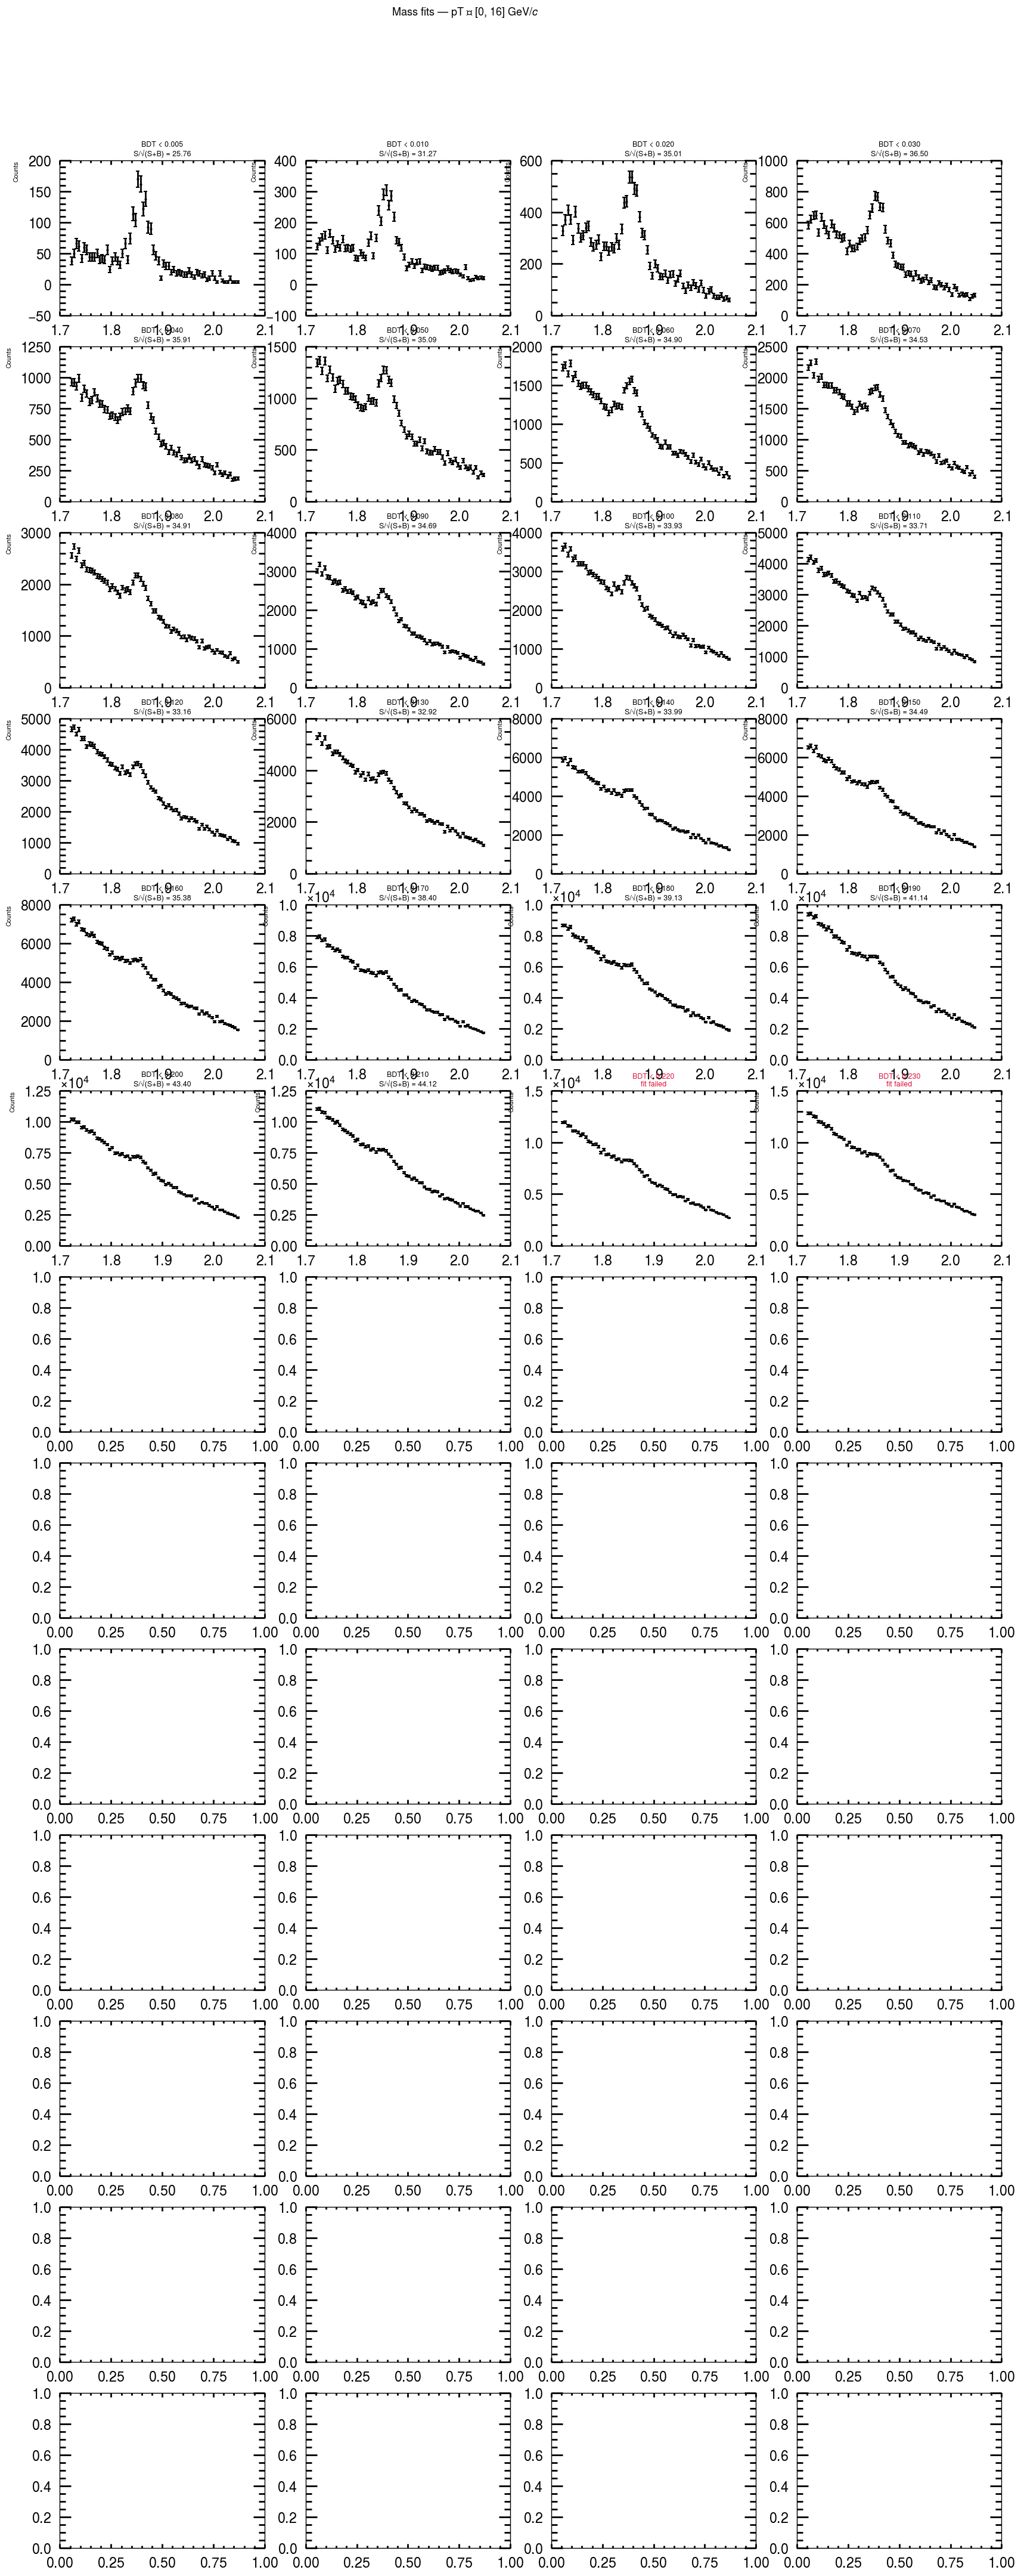

In [24]:
all_rows   = []   # collect for summary table
best_cuts  = {}   # pt_label → best BDT cut

for pt_key in pt_dirs:
    pt_lo, pt_hi = parse_pt_from_dirname(pt_key)
    pt_label = f"{pt_lo:.1f}–{pt_hi:.1f} GeV/c"

    # Get histogram names for this pT bin from the flat key list
    hist_names = sorted(
        [k.split("/")[1] for k in all_keys
         if k.startswith(pt_key + "/hMass_")],
        key=lambda s: parse_bdt_from_histname(s) or 0.
    )
    bdt_cuts_this = [parse_bdt_from_histname(n) for n in hist_names
                     if parse_bdt_from_histname(n) is not None]

    # Access histograms via full path
    def get_hist(hname):
        return f[f"{pt_key}/{hname}"]

    print(f"\n{'─'*60}")
    print(f"pT ∈ [{pt_lo:.0f}, {pt_hi:.0f}] GeV/c  —  {len(bdt_cuts_this)} BDT cuts")
    print(f"{'─'*60}")

    # ── Mass fit grid ─────────────────────────────────────────────────────────
    n_cols = min(4, len(bdt_cuts_this))
    n_rows = (len(bdt_cuts_this) + n_cols - 1) // n_cols
    fig_mass, axes_mass = plt.subplots(n_rows, n_cols,
                                       figsize=(5*n_cols, 4*n_rows),
                                       squeeze=False)
    fig_mass.suptitle(f"Mass fits — pT ∈ [{pt_lo:.0f}, {pt_hi:.0f}] GeV/$c$",
                      fontsize=13)

    cuts, signifs, errs = [], [], []
    best_sig, best_cut, best_fitter, best_h = 0., None, None, None

    for i_bdt, (hname, bdt_cut) in enumerate(zip(hist_names, bdt_cuts_this)):
        h_up  = get_hist(hname)
        label = f"pt{pt_lo:.1f}_{pt_hi:.1f}_bdt{bdt_cut:.3f}"

        res, fitter = fit_histogram(h_up, pt_lo, pt_hi, bdt_cut, label)

        cuts.append(bdt_cut)
        signifs.append(res["significance"])
        errs.append(res["significance_err"])

        status = "✓" if res["success"] else "✗"
        print(f"  {status}  BDT < {bdt_cut:.3f}  |"
              f"  S={res['S']:8.1f}  B={res['B']:8.1f}"
              f"  S/√(S+B)={res['significance']:6.3f} ± {res['significance_err']:.3f}"
              f"  σ={res['sigma']*1000:.1f} MeV")

        # Only draw grid cell if fit succeeded
        ax = axes_mass[i_bdt // n_cols][i_bdt % n_cols]
        centres, values, errors = uproot_th1_to_numpy(h_up)
        mask = (centres >= FIT_RANGE[0]) & (centres <= FIT_RANGE[1])
        ax.errorbar(centres[mask], values[mask], yerr=errors[mask],
                    fmt="k.", markersize=3)
        if res["success"]:
            ax.set_title(f"BDT < {bdt_cut:.3f}\n"
                         f"S/√(S+B) = {res['significance']:.2f}", fontsize=9)
            if res["significance"] > best_sig:
                best_sig, best_cut = res["significance"], bdt_cut
                best_fitter, best_h = fitter, h_up
        else:
            ax.set_title(f"BDT < {bdt_cut:.3f}\nfit failed", fontsize=9,
                         color="crimson")

        ax.set_xlabel(r"$M(K\pi)$ [GeV/$c^2$]", fontsize=8)
        ax.set_ylabel("Counts", fontsize=8)

        all_rows.append({"pT bin": pt_label, "BDT_bkg <": bdt_cut, **res})

    # Hide unused grid cells
    for k in range(len(bdt_cuts_this), n_rows * n_cols):
        axes_mass[k // n_cols][k % n_cols].set_visible(False)

    fig_mass.tight_layout()
    #fig_mass.savefig(os.path.join(OUTDIR, f"massplots_pt{pt_lo:.0f}_{pt_hi:.0f}.pdf"))
    #plt.show()
    plt.close(fig_mass)

    # ── Significance scan plot ────────────────────────────────────────────────
    valid_mask = [s > 0 for s in signifs]
    valid_cuts   = [c for c, m in zip(cuts,   valid_mask) if m]
    valid_signifs = [s for s, m in zip(signifs, valid_mask) if m]
    valid_errs   = [e for e, m in zip(errs,   valid_mask) if m]

    if valid_cuts:
        fig_sc, ax_sc = plt.subplots(figsize=(7, 4))
        ax_sc.errorbar(valid_cuts, valid_signifs, yerr=valid_errs,
                       fmt=".-", color="royalblue", capsize=2)
        if best_cut is not None:
            ax_sc.axvline(best_cut, color="crimson", linestyle="--",
                          label=f"Best: BDT < {best_cut:.2f}  →  S/√(S+B) = {best_sig:.2f}")
        ax_sc.set_xlabel("BDT background score upper cut")
        ax_sc.set_ylabel(r"$S\,/\,\sqrt{S+B}$")
        ax_sc.set_title(rf"Significance scan — $p_T \in [{pt_lo:.1f},\, {pt_hi:.1f}]$ GeV/$c$")
        ax_sc.set_xlim(min(valid_cuts) - 0.01, max(valid_cuts) + 0.01)
        ax_sc.legend(fontsize=9)
        fig_sc.tight_layout()
        fig_sc.savefig(os.path.join(OUTDIR, f"scan_pt{pt_lo:.1f}_{pt_hi:.1f}.pdf"))
        plt.show()
    else:
        print("  No successful fits to plot for significance scan.")

    # ── S/B scan plot ─────────────────────────────────────────────────────────
    valid_sb = [res["S"] / res["B"] if res["B"] > 0 else 0
                for res in [all_rows[i] for i in range(len(all_rows) - len(cuts), len(all_rows))]]
    valid_mask_sb = [v > 0 for v in valid_sb]
    valid_cuts_sb = [c for c, m in zip(cuts,   valid_mask_sb) if m]
    valid_sb_vals = [v for v, m in zip(valid_sb, valid_mask_sb) if m]

    if valid_cuts_sb:
        fig_sb, ax_sb = plt.subplots(figsize=(7, 4))
        ax_sb.plot(valid_cuts_sb, valid_sb_vals,
                ".-", color="seagreen")
        if best_cut is not None:
            ax_sb.axvline(best_cut, color="crimson", linestyle="--",
                        label=f"Best significance: BDT < {best_cut:.2f}")
        ax_sb.set_xlabel("BDT background score upper cut")
        ax_sb.set_ylabel(r"$S\,/\,B$")
        ax_sb.set_title(rf"S/B scan — $p_T \in [{pt_lo:.1f},\, {pt_hi:.1f}]$ GeV/$c$")
        ax_sb.set_xlim(min(valid_cuts_sb) - 0.01, max(valid_cuts_sb) + 0.01)
        ax_sb.legend(fontsize=9)
        fig_sb.tight_layout()
        fig_sb.savefig(os.path.join(OUTDIR, f"sb_scan_pt{pt_lo:.1f}_{pt_hi:.1f}.pdf"))
        plt.show()
    else:
        print("  No successful fits to plot for S/B scan.")

print("\n✓ Fit loop complete.")

## Interactive: inspect one bin in detail

Use this cell to look at a specific (pT bin, BDT cut) combination and get the
full flarefly fit plot with the pull panel.

INFO: Performing FIT
I MnSeedGenerator Computing seed using NumericalGradient calculator


I MnSeedGenerator Evaluated function and gradient in 910.382 ms
I MnSeedGenerator Initial state: FCN =             10000 Edm =       1269.350106 NCalls =     17
I MnSeedGenerator Initial state  
  Minimum value : 10000
  Edm           : 1269.350106
  Internal parameters:	[     -0.927295218      2.684641201    -0.5235987756             -1.5]	
  Internal gradient  :	[     -674.1427853      18573.51772      154.0625303      665.8626149]	
  Internal covariance matrix:
[[  0.00034211781              0              0              0]
 [              0  1.3731135e-06              0              0]
 [              0              0   0.0040111616              0]
 [              0              0              0   0.0098179679]]]
I VariableMetricBuilder Start iterating until Edm is < 0.001 with call limit = 680
I VariableMetricBuilder    0 - FCN =             10000 Edm =       1269.350106 NCalls =     17
I VariableMetricBuilder    1 - FCN =       8791.087408 Edm =       73.74421363 NCalls =     27


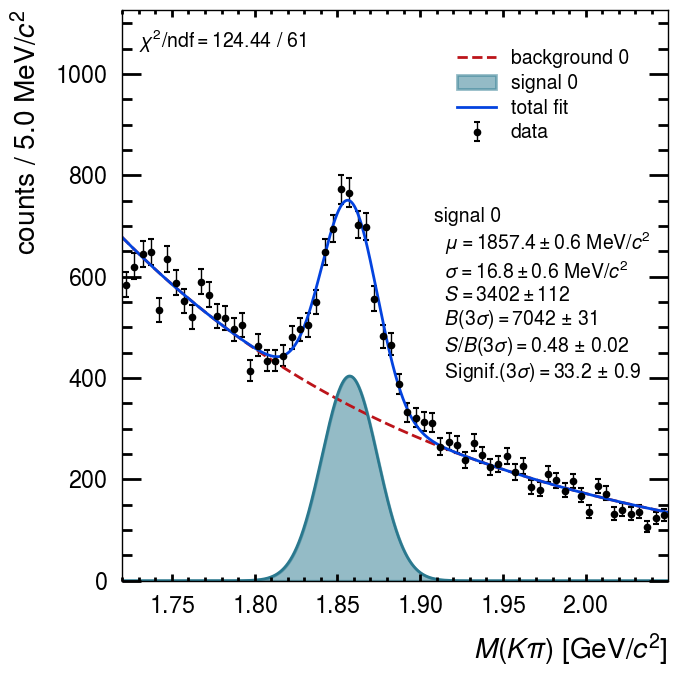


Fit results:
  Mean  = 1857.39 ± 0.57 MeV/c²
  Sigma = 16.80 ± 0.62 MeV/c²
  S     = 3401.8 ± 112.2
  B     = 4668.4 ± 20.5
  S/√(S+B) = 36.496 ± 0.958
  χ²/ndf   = 2.04


In [26]:
# ── Edit these two lines ──────────────────────────────────────────────────────
PT_KEY  = pt_dirs[0]    # e.g. pt_dirs[2] for the third pT bin
BDT_CUT = 0.03          # must match one of the cuts in projections.root
# ─────────────────────────────────────────────────────────────────────────────

pt_lo, pt_hi = parse_pt_from_dirname(PT_KEY)
hname  = f"hMass_bdt{int(BDT_CUT*1000):04d}"
h_up   = f[PT_KEY][hname]
label  = f"inspect_pt{pt_lo:.0f}_{pt_hi:.0f}_bdt{BDT_CUT:.2f}"

res, fitter = fit_histogram(h_up, pt_lo, pt_hi, BDT_CUT, label)

if fitter is not None:
    fig, axes = fitter.plot_mass_fit(
        style="ATLAS",
        show_extra_info=True,
        axis_title=r"$M(K\pi)$ [GeV/$c^2$]",
        extra_info_loc=['upper left', 'center right'],
        label_fit_model=(
            f"pT ∈ [{pt_lo:.0f}, {pt_hi:.0f}] GeV/$c$\n"
            f"BDT_bkg < {BDT_CUT:.2f}"
        ),
    )
    plt.tight_layout()
    plt.show()

    print(f"\nFit results:")
    print(f"  Mean  = {res['mean']*1000:.2f} ± {res['mean_err']*1000:.2f} MeV/c²")
    print(f"  Sigma = {res['sigma']*1000:.2f} ± {res['sigma_err']*1000:.2f} MeV/c²")
    print(f"  S     = {res['S']:.1f} ± {res['S_err']:.1f}")
    print(f"  B     = {res['B']:.1f} ± {res['B_err']:.1f}")
    print(f"  S/√(S+B) = {res['significance']:.3f} ± {res['significance_err']:.3f}")
    print(f"  χ²/ndf   = {res['chi2_ndf']:.2f}")
else:
    print("Fit did not converge.")

INFO: Performing FIT
I MnSeedGenerator Computing seed using NumericalGradient calculator


I MnSeedGenerator Evaluated function and gradient in 919.966 ms
I MnSeedGenerator Initial state: FCN =             10000 Edm =       4715.598951 NCalls =     17
I MnSeedGenerator Initial state  
  Minimum value : 10000
  Edm           : 4715.598951
  Internal parameters:	[     -0.927295218      2.684641201    -0.5235987756             -1.5]	
  Internal gradient  :	[      2299.808151      14508.59233      -350.154669      1012.796249]	
  Internal covariance matrix:
[[  0.00022646015              0              0              0]
 [              0  3.7985923e-05              0              0]
 [              0              0   0.0078786575              0]
 [              0              0              0   0.0084841056]]]
I VariableMetricBuilder Start iterating until Edm is < 0.001 with call limit = 680
I VariableMetricBuilder    0 - FCN =             10000 Edm =       4715.598951 NCalls =     17
I VariableMetricBuilder    1 - FCN =       7531.094333 Edm =       37.36076785 NCalls =     30


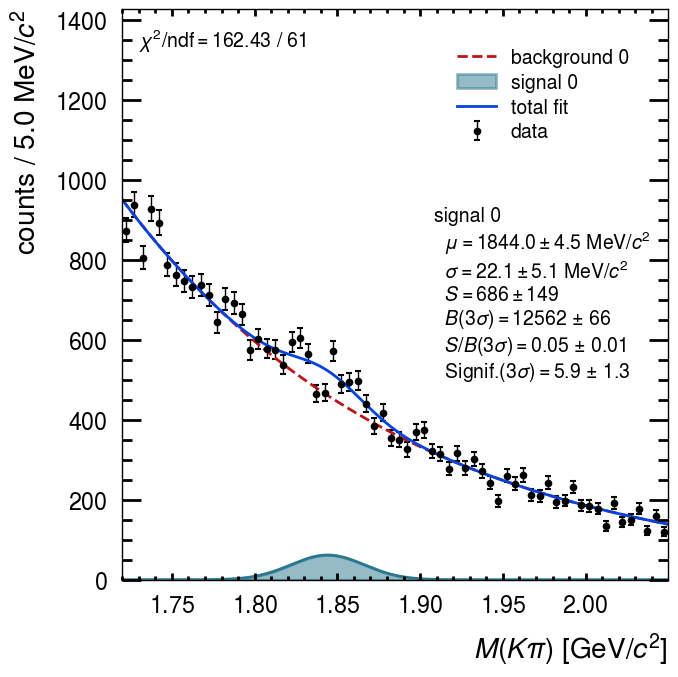

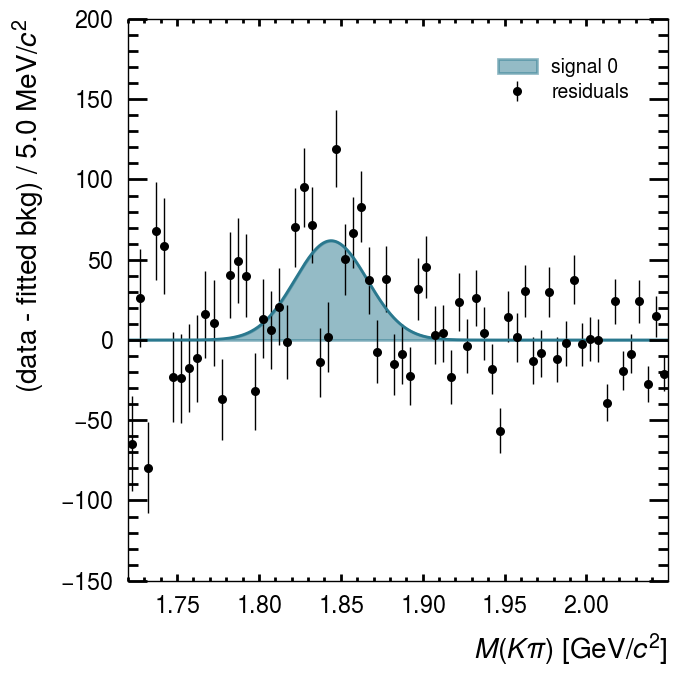


pT 0.0–1.0 GeV/c  (BDT_bkg < 0.080)
  Mean     = 1844.04 ± 4.46 MeV/c²
  Sigma    = 22.13 ± 5.12 MeV/c²
  S        = 686.4 ± 149.0
  B        = 8260.1 ± 43.1
  S/√(S+B) = 6.939 ± 1.451
  χ²/ndf   = 2.66
INFO: Performing FIT
I MnSeedGenerator Computing seed using NumericalGradient calculator
I MnSeedGenerator Evaluated function and gradient in 1.25606 s
I MnSeedGenerator Initial state: FCN =             10000 Edm =       1425.046021 NCalls =     17
I MnSeedGenerator Initial state  
  Minimum value : 10000
  Edm           : 1425.046021
  Internal parameters:	[     -0.927295218      2.684641201    -0.5235987756             -1.5]	
  Internal gradient  :	[      797.3567107      13889.12113      -144.308289      726.0057138]	
  Internal covariance matrix:
[[  0.00027580054              0              0              0]
 [              0  3.0696264e-06              0              0]
 [              0              0   0.0054877484              0]
 [              0              0              0

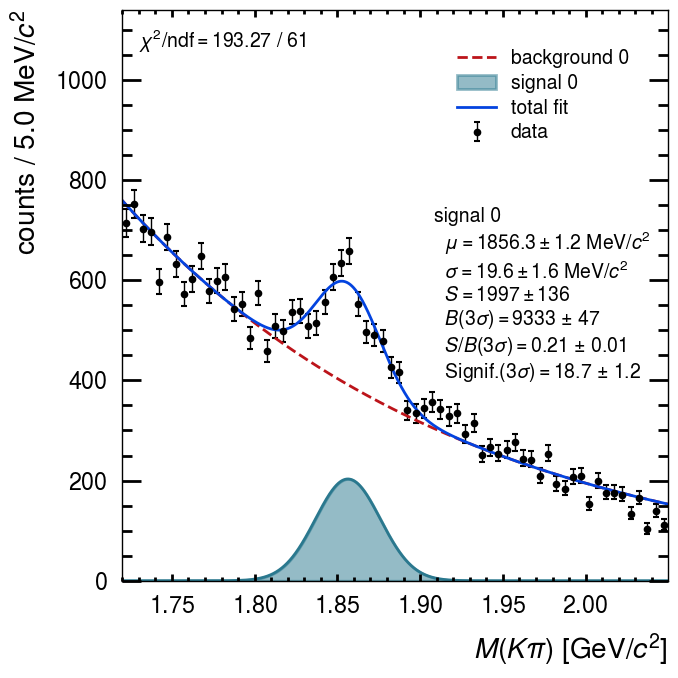

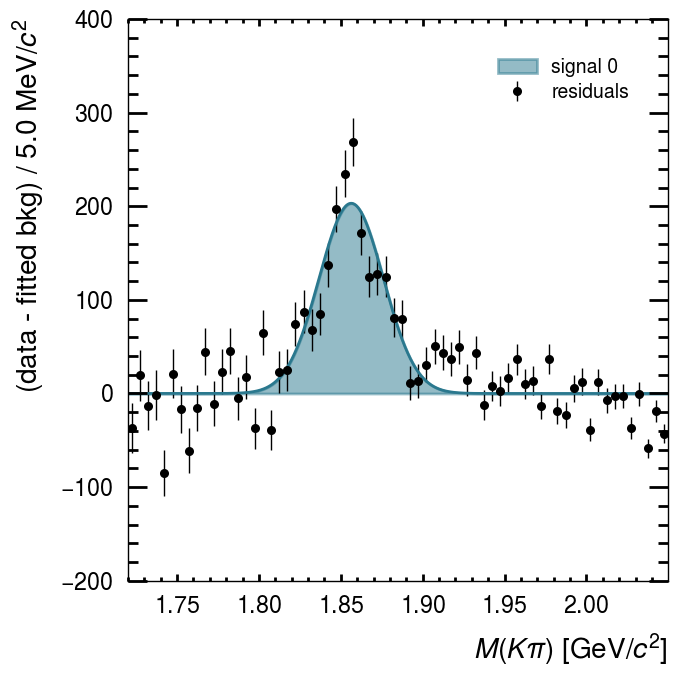


pT 1.0–2.0 GeV/c  (BDT_bkg < 0.050)
  Mean     = 1856.34 ± 1.18 MeV/c²
  Sigma    = 19.60 ± 1.60 MeV/c²
  S        = 1996.8 ± 135.5
  B        = 6175.3 ± 31.0
  S/√(S+B) = 21.202 ± 1.270
  χ²/ndf   = 3.17
INFO: Performing FIT
I MnSeedGenerator Computing seed using NumericalGradient calculator
I MnSeedGenerator Evaluated function and gradient in 843.892 ms
I MnSeedGenerator Initial state: FCN =             10000 Edm =        253.953604 NCalls =     17
I MnSeedGenerator Initial state  
  Minimum value : 10000
  Edm           : 253.953604
  Internal parameters:	[     -0.927295218      2.684641201    -0.5235987756             -1.5]	
  Internal gradient  :	[     -313.9177694      6256.176111      60.18775003       187.319829]	
  Internal covariance matrix:
[[  0.00078018685              0              0              0]
 [              0  3.1923659e-06              0              0]
 [              0              0   0.0093698639              0]
 [              0              0             

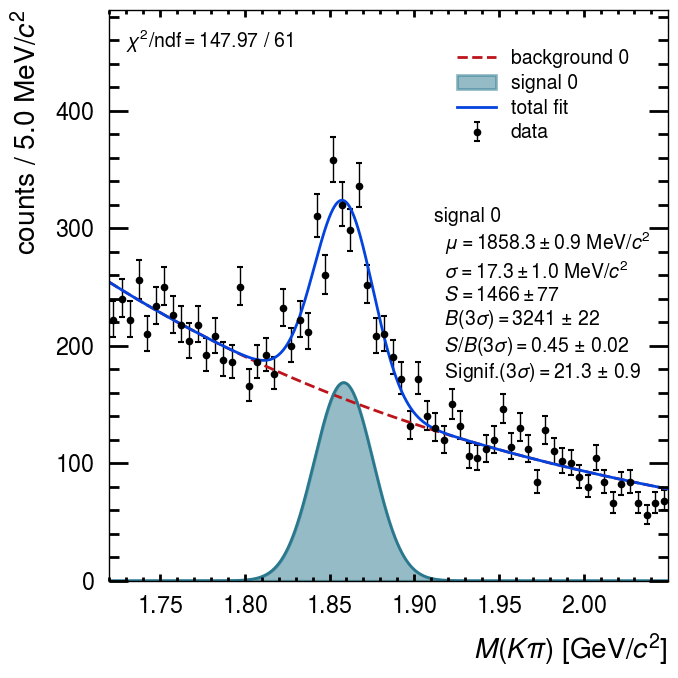

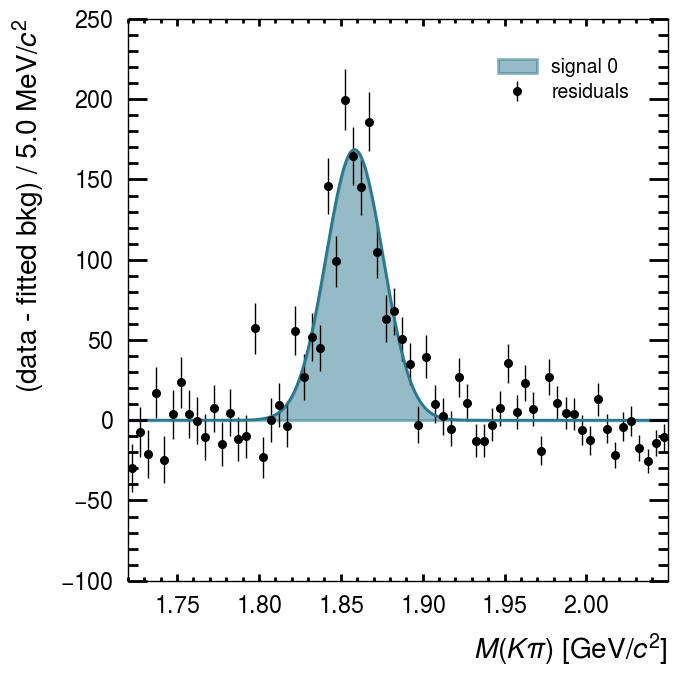


pT 2.0–3.0 GeV/c  (BDT_bkg < 0.050)
  Mean     = 1858.33 ± 0.92 MeV/c²
  Sigma    = 17.34 ± 1.04 MeV/c²
  S        = 1466.1 ± 77.2
  B        = 2154.1 ± 14.7
  S/√(S+B) = 23.475 ± 0.994
  χ²/ndf   = 2.43
INFO: Performing FIT
I MnSeedGenerator Computing seed using NumericalGradient calculator
I MnSeedGenerator Evaluated function and gradient in 833.905 ms
I MnSeedGenerator Initial state: FCN =             10000 Edm =       235.8294849 NCalls =     17
I MnSeedGenerator Initial state  
  Minimum value : 10000
  Edm           : 235.8294849
  Internal parameters:	[     -0.927295218      2.684641201    -0.5235987756             -1.5]	
  Internal gradient  :	[     -312.8466415      2486.304286      76.59663842      50.39632527]	
  Internal covariance matrix:
[[   0.0047713837              0              0              0]
 [              0  6.3307053e-06              0              0]
 [              0              0    0.030547946              0]
 [              0              0             

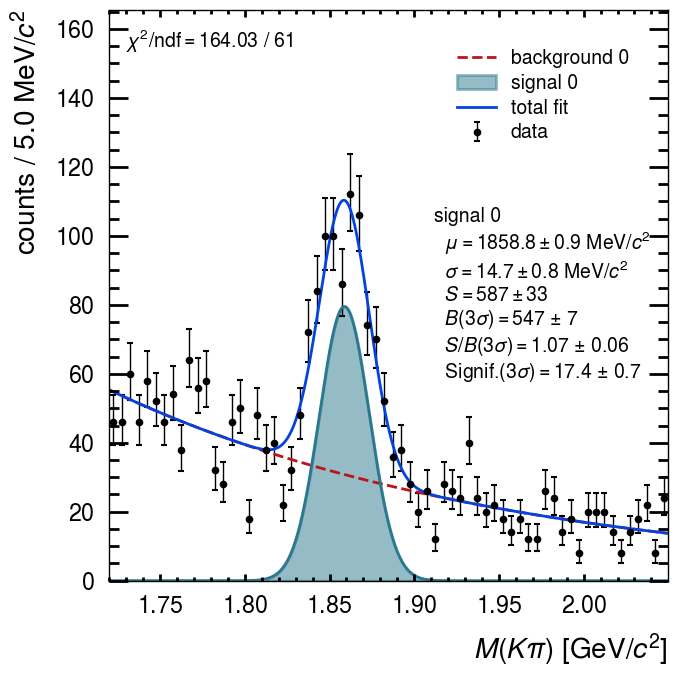

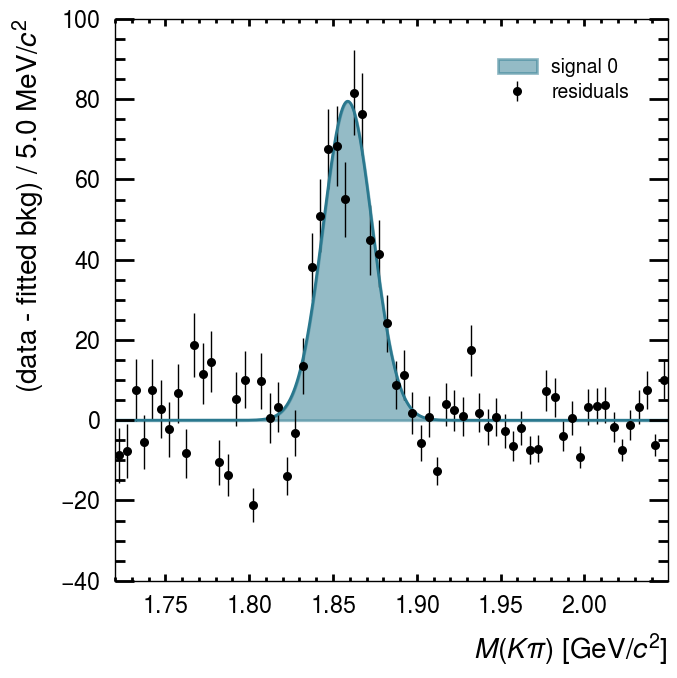


pT 3.0–4.0 GeV/c  (BDT_bkg < 0.040)
  Mean     = 1858.78 ± 0.94 MeV/c²
  Sigma    = 14.72 ± 0.80 MeV/c²
  S        = 586.5 ± 32.6
  B        = 363.4 ± 4.6
  S/√(S+B) = 18.425 ± 0.714
  χ²/ndf   = 2.69
pT 4.0–5.0 GeV/c: no successful fit, skipping.
INFO: Performing FIT
I MnSeedGenerator Computing seed using NumericalGradient calculator
I MnSeedGenerator Evaluated function and gradient in 872.199 ms
I MnSeedGenerator Initial state: FCN =             10000 Edm =       64.60662043 NCalls =     17
I MnSeedGenerator Initial state  
  Minimum value : 10000
  Edm           : 64.60662043
  Internal parameters:	[     -0.927295218      2.684641201    -0.5235987756             -1.5]	
  Internal gradient  :	[     -113.1064667      1227.664579      11.07058781      24.13485278]	
  Internal covariance matrix:
[[   0.0086467885              0              0              0]
 [              0  2.0831967e-05              0              0]
 [              0              0    0.035593636              0]
 

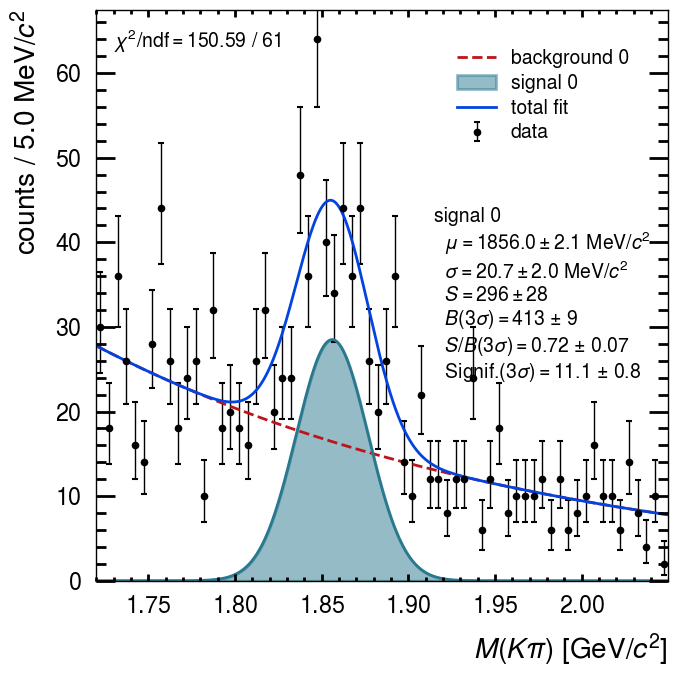

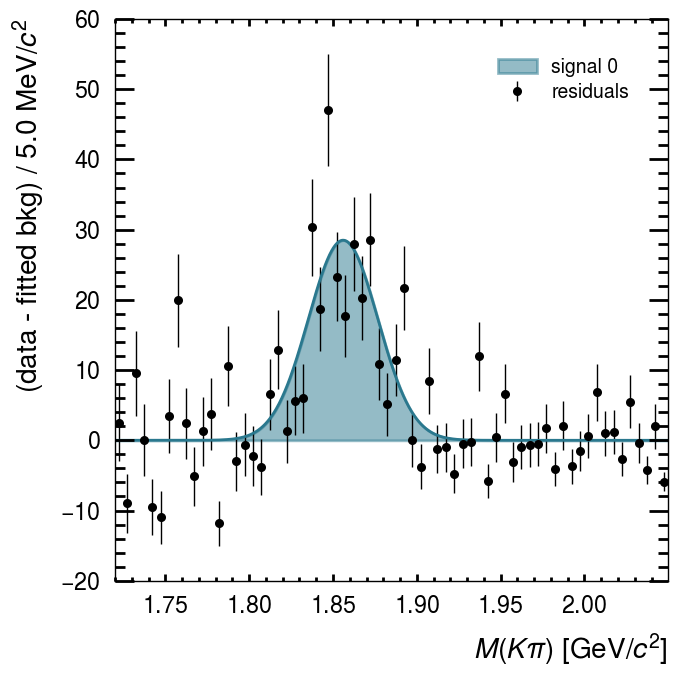


pT 5.0–7.0 GeV/c  (BDT_bkg < 0.100)
  Mean     = 1856.03 ± 2.12 MeV/c²
  Sigma    = 20.73 ± 2.04 MeV/c²
  S        = 296.1 ± 28.3
  B        = 273.7 ± 5.8
  S/√(S+B) = 11.983 ± 0.857
  χ²/ndf   = 2.47
INFO: Performing FIT
I MnSeedGenerator Computing seed using NumericalGradient calculator
I MnSeedGenerator Evaluated function and gradient in 855.028 ms
I MnSeedGenerator Initial state: FCN =             10000 Edm =       12.88196746 NCalls =     17
I MnSeedGenerator Initial state  
  Minimum value : 10000
  Edm           : 12.88196746
  Internal parameters:	[     -0.927295218      2.684641201    -0.5235987756             -1.5]	
  Internal gradient  :	[     -33.87234034      217.5537968      4.019238524      6.584095525]	
  Internal covariance matrix:
[[    0.020843045              0              0              0]
 [              0  5.9707491e-05              0              0]
 [              0              0      0.1658845              0]
 [              0              0              0 

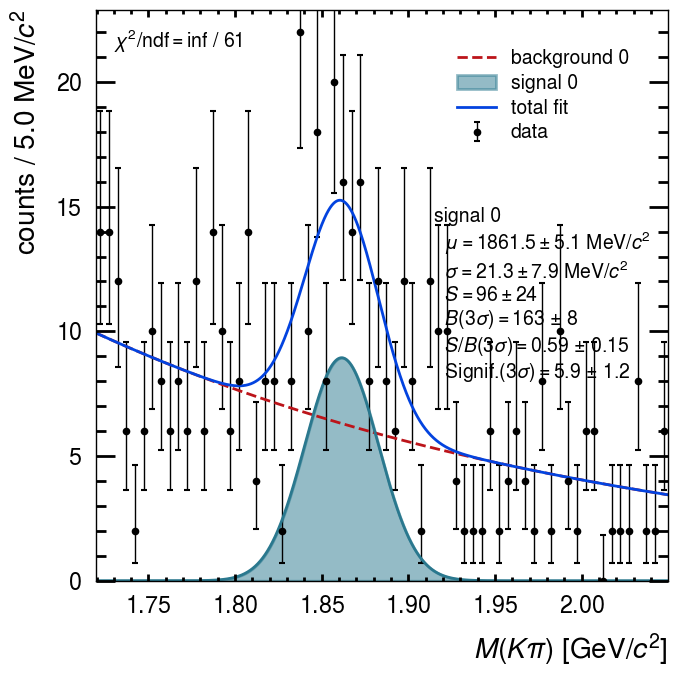

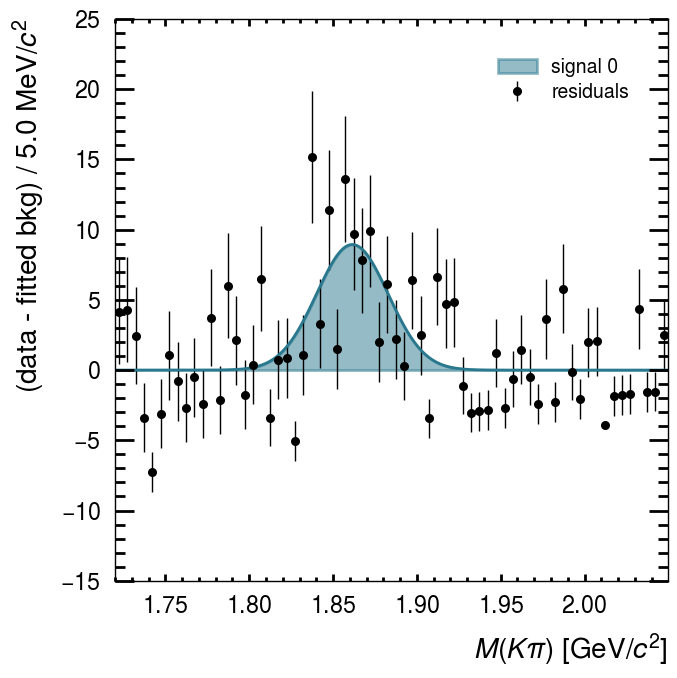


pT 7.0–12.0 GeV/c  (BDT_bkg < 0.150)
  Mean     = 1861.47 ± 5.07 MeV/c²
  Sigma    = 21.34 ± 7.92 MeV/c²
  S        = 95.6 ± 24.2
  B        = 107.9 ± 5.2
  S/√(S+B) = 6.467 ± 1.265
  χ²/ndf   = inf


In [ ]:
# ── Manual best cut selection ─────────────────────────────────────────────────
# Set your chosen BDT background score cut for each pT bin.
# Keys must match the pt_label format: "{lo:.1f}–{hi:.1f} GeV/c"
manual_best_cuts = {
    "0.0–1.0 GeV/c"  : 0.08,
    "1.0–2.0 GeV/c"  : 0.05,
    "2.0–3.0 GeV/c"  : 0.05,
    "3.0–4.0 GeV/c"  : 0.04,
    "5.0–7.0 GeV/c"  : 0.10,
    "7.0–12.0 GeV/c"  : 0.15
}

for pt_key in pt_dirs:
    pt_lo, pt_hi = parse_pt_from_dirname(pt_key)
    pt_label = f"{pt_lo:.1f}–{pt_hi:.1f} GeV/c"

    best_cut = manual_best_cuts.get(pt_label)
    if best_cut is None:
        print(f"pT {pt_label}: no successful fit, skipping.")
        continue

    hname = f"hMass_bdt{int(best_cut * 1000):04d}"
    h_up  = f[f"{pt_key}/{hname}"]
    label = f"best_pt{pt_lo:.1f}_{pt_hi:.1f}_bdt{best_cut:.3f}"

    res, fitter = fit_histogram(h_up, pt_lo, pt_hi, best_cut, label)

    if fitter is not None:
        fig, axes = fitter.plot_mass_fit(
            style="ATLAS",
            show_extra_info=True,
            axis_title=r"$M(K\pi)$ [GeV/$c^2$]",
            extra_info_loc=["upper left", "center right"],
            label_fit_model=(
                rf"$p_T \in [{pt_lo:.1f},\, {pt_hi:.1f}]$ GeV/$c$"
                f"\nBDT_bkg < {best_cut:.3f}"
            ),
        )
        plt.tight_layout()
        fig.savefig(os.path.join(OUTDIR, f"best_fit_pt{pt_lo:.1f}_{pt_hi:.1f}.pdf"))
        plt.show()

        if fitter is not None:
            fig_raw = fitter.plot_raw_residuals(style="ATLAS")
            plt.tight_layout()
            plt.show()

        print(f"\npT {pt_label}  (BDT_bkg < {best_cut:.3f})")
        print(f"  Mean     = {res['mean']*1000:.2f} ± {res['mean_err']*1000:.2f} MeV/c²")
        print(f"  Sigma    = {res['sigma']*1000:.2f} ± {res['sigma_err']*1000:.2f} MeV/c²")
        print(f"  S        = {res['S']:.1f} ± {res['S_err']:.1f}")
        print(f"  B        = {res['B']:.1f} ± {res['B_err']:.1f}")
        print(f"  S/√(S+B) = {res['significance']:.3f} ± {res['significance_err']:.3f}")
        print(f"  χ²/ndf   = {res['chi2_ndf']:.2f}")
    else:
        print(f"pT {pt_label}: fit did not converge at best cut {best_cut:.3f}.")

### Pull residuals for the selected fit

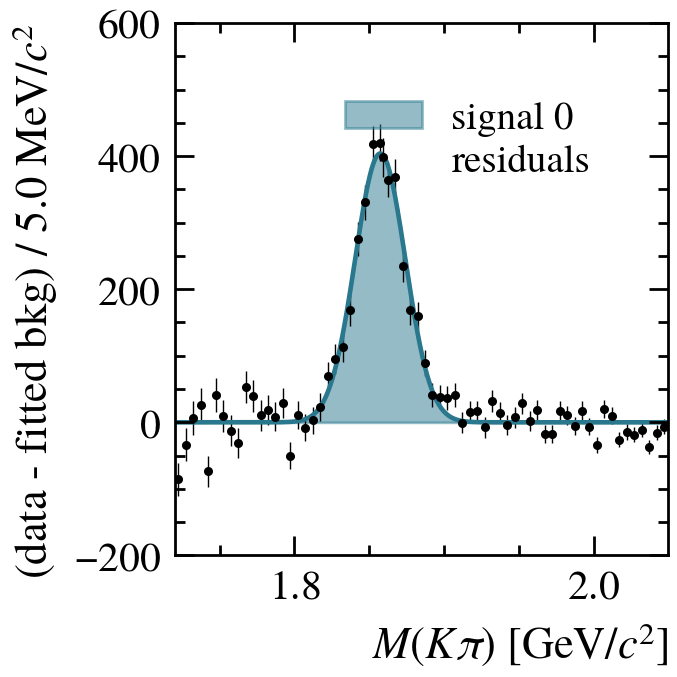

In [29]:
if fitter is not None:
    fig_res = fitter.plot_raw_residuals()
    plt.tight_layout()
    plt.show()

INFO: Performing FIT
I MnSeedGenerator Computing seed using NumericalGradient calculator


I MnSeedGenerator Evaluated function and gradient in 914.972 ms
I MnSeedGenerator Initial state: FCN =             10000 Edm =       4715.598951 NCalls =     17
I MnSeedGenerator Initial state  
  Minimum value : 10000
  Edm           : 4715.598951
  Internal parameters:	[     -0.927295218      2.684641201    -0.5235987756             -1.5]	
  Internal gradient  :	[      2299.808151      14508.59233      -350.154669      1012.796249]	
  Internal covariance matrix:
[[  0.00022646015              0              0              0]
 [              0  3.7985923e-05              0              0]
 [              0              0   0.0078786575              0]
 [              0              0              0   0.0084841056]]]
I VariableMetricBuilder Start iterating until Edm is < 0.001 with call limit = 680
I VariableMetricBuilder    0 - FCN =             10000 Edm =       4715.598951 NCalls =     17
I VariableMetricBuilder    1 - FCN =       7531.094333 Edm =       37.36076785 NCalls =     30


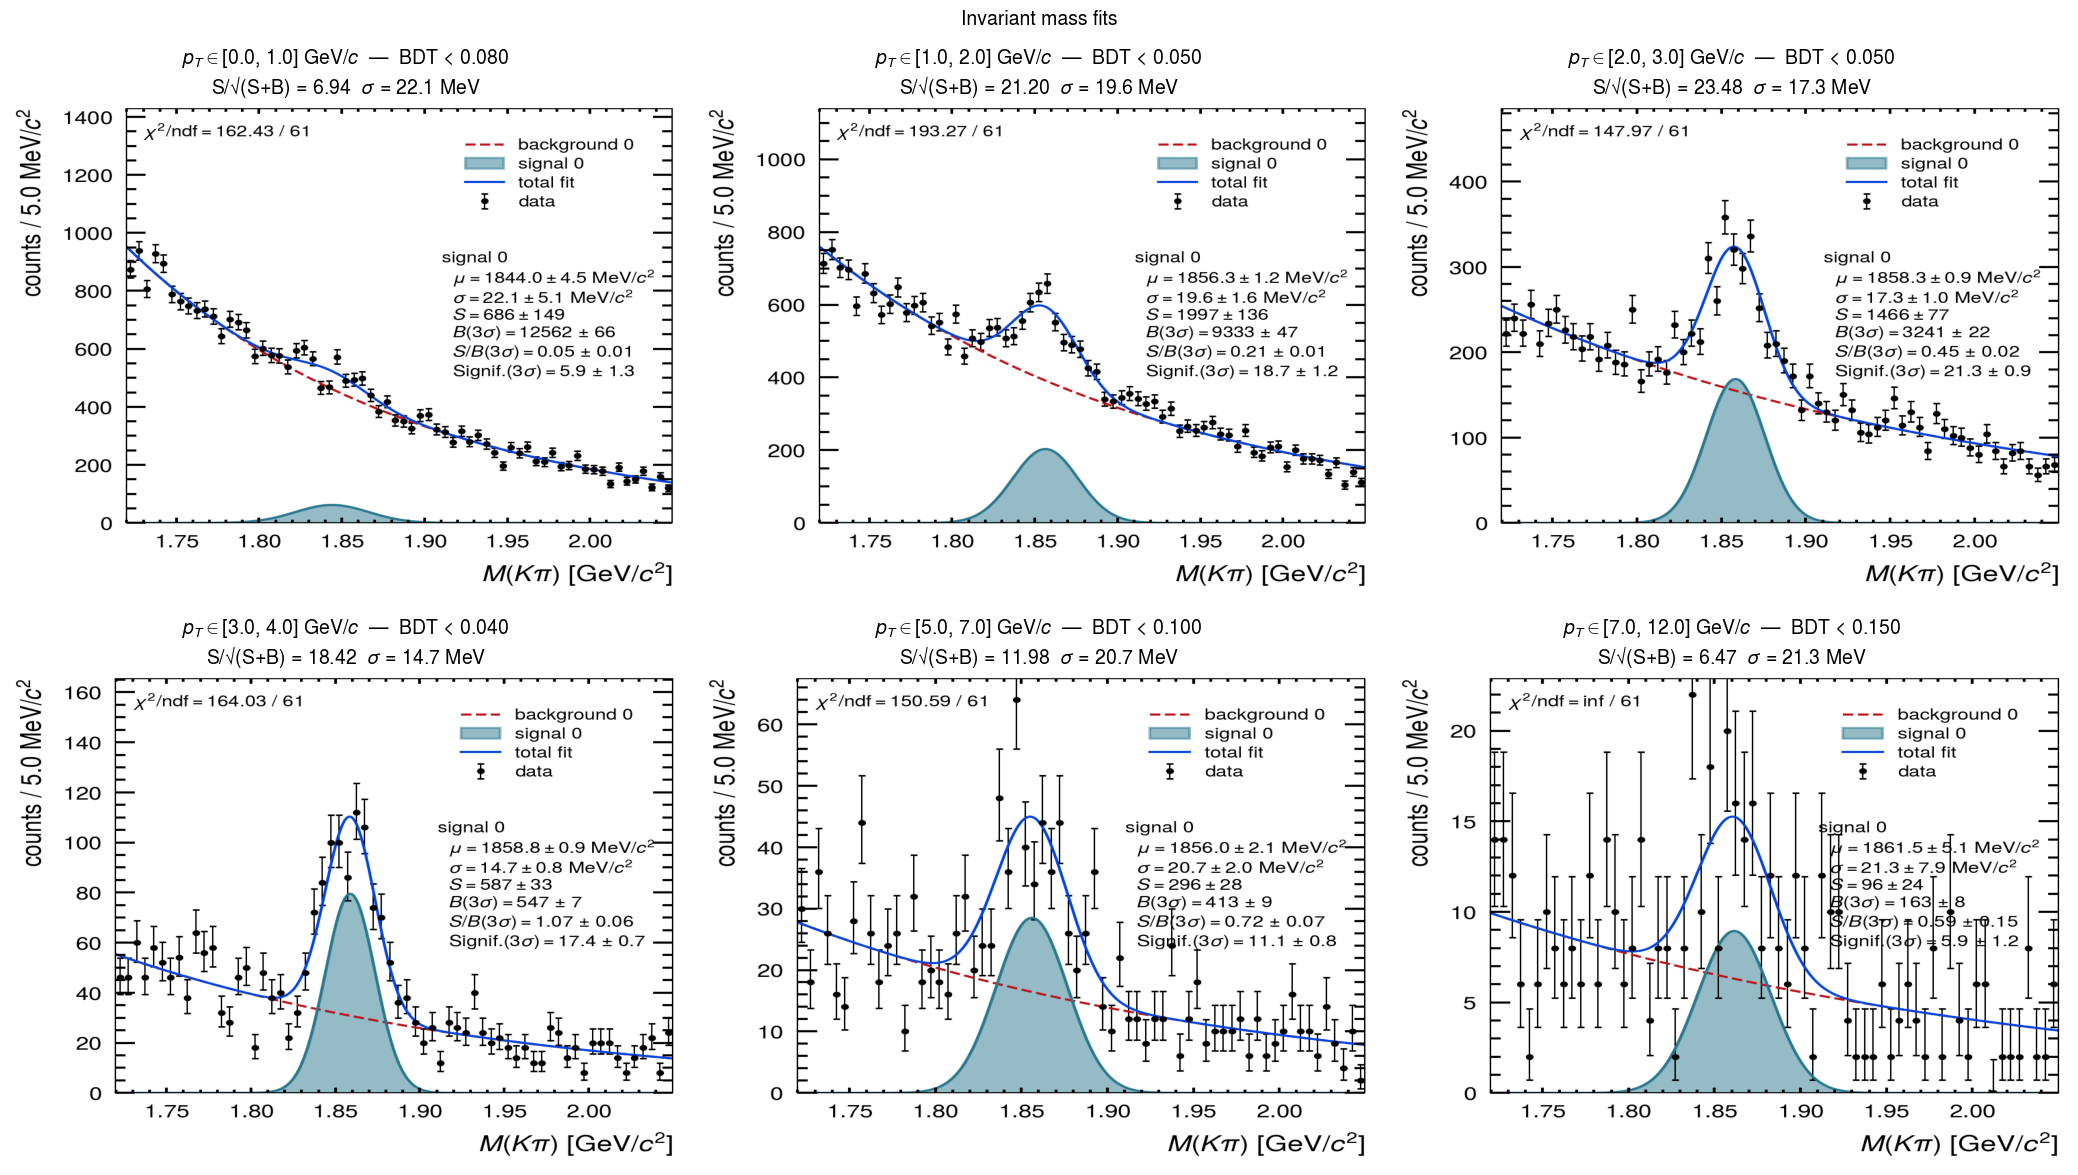

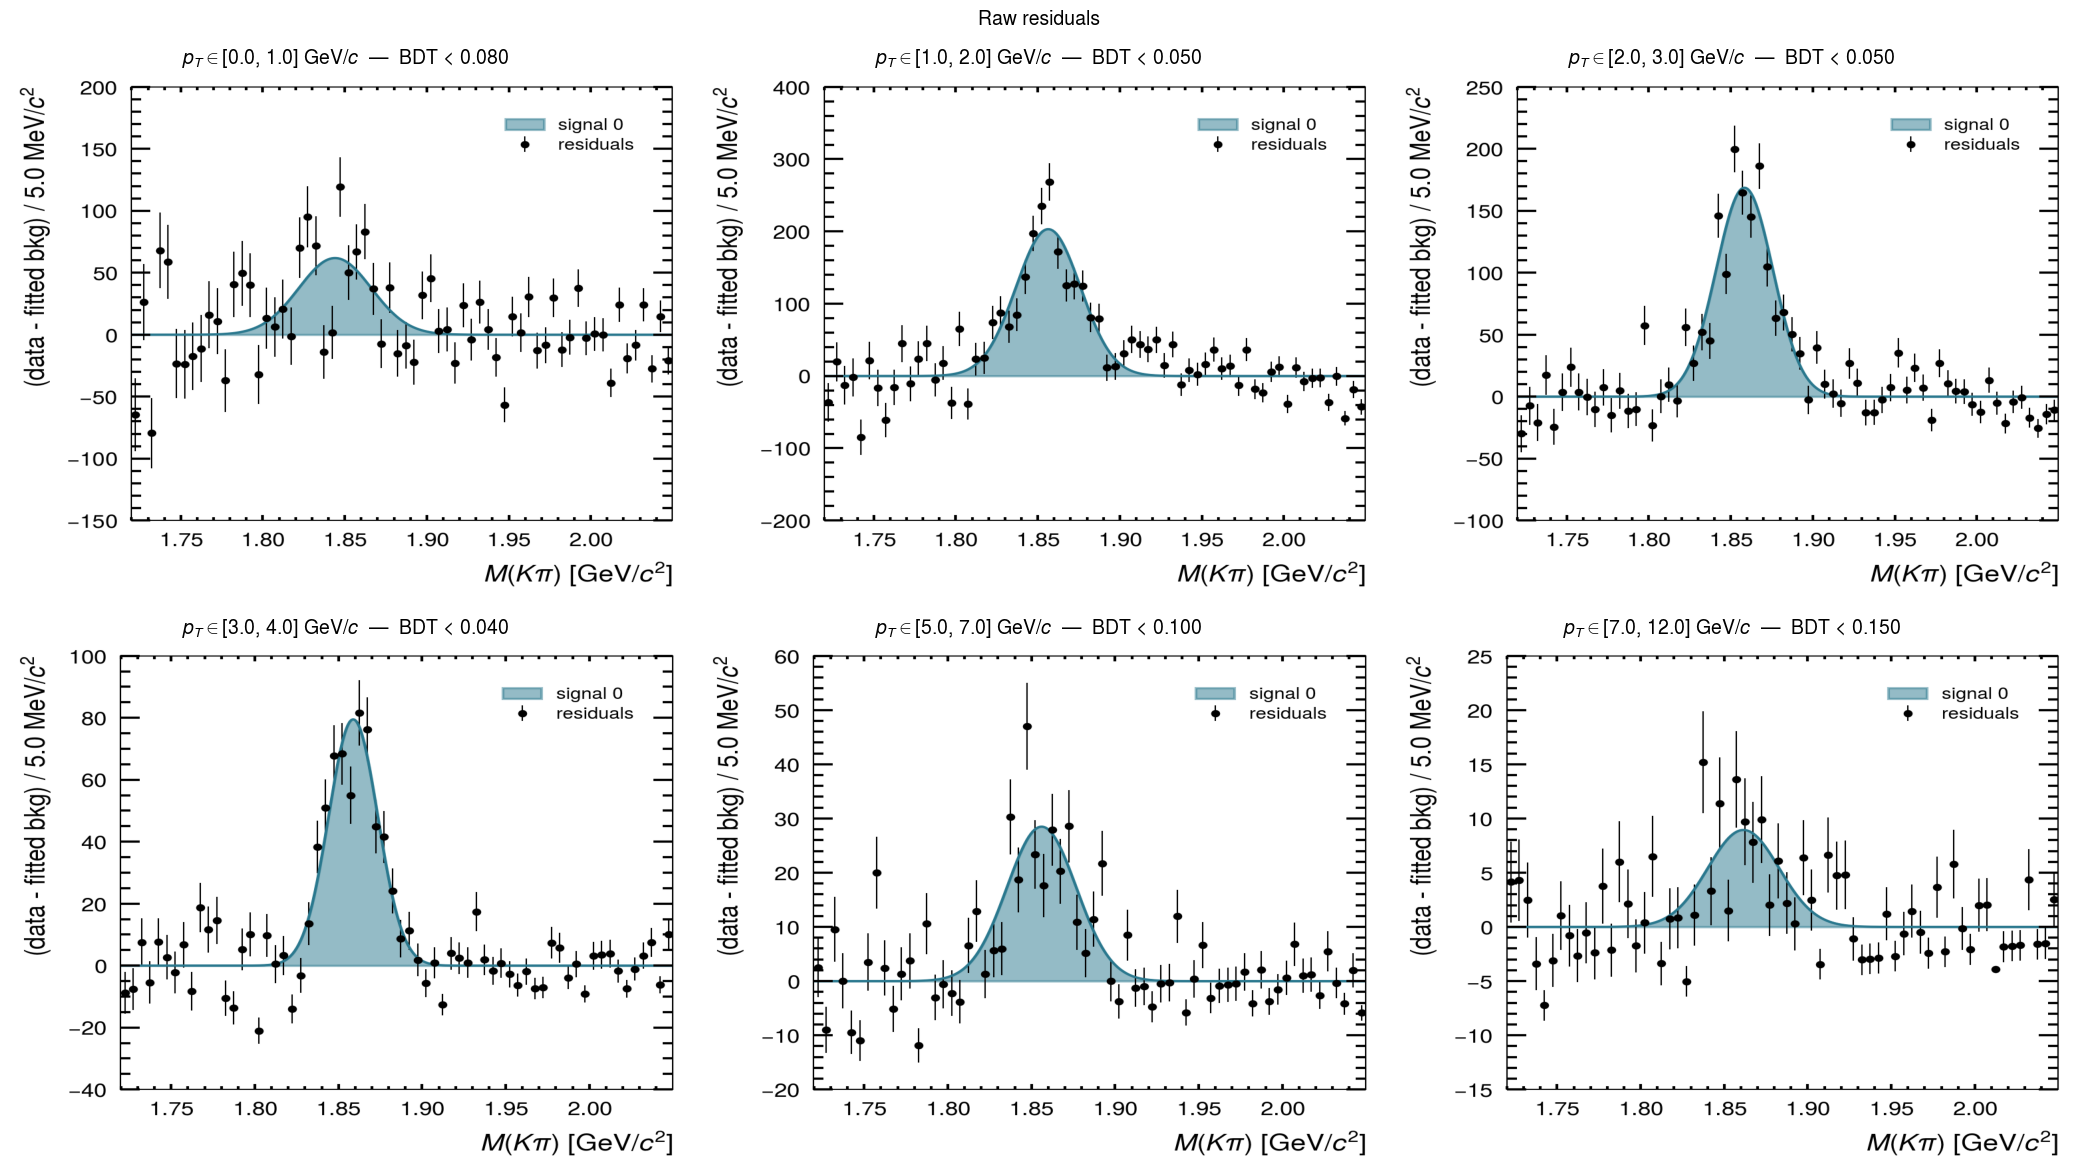

In [ ]:
import io
import numpy as np

n_pt_manual = len(manual_best_cuts)
n_cols = min(3, n_pt_manual)
n_rows = (n_pt_manual + n_cols - 1) // n_cols

fig_fits, axes_fits = plt.subplots(n_rows, n_cols,
                                    figsize=(7*n_cols, 6*n_rows),
                                    squeeze=False)
fig_res,  axes_res  = plt.subplots(n_rows, n_cols,
                                    figsize=(7*n_cols, 6*n_rows),
                                    squeeze=False)
fig_fits.suptitle("Invariant mass fits",     fontsize=14)
fig_res.suptitle( "Raw residuals", fontsize=14)

def fig_to_img(fig):
    """Render a matplotlib figure to a numpy image array."""
    buf = io.BytesIO()
    fig.savefig(buf, format="png", dpi=150, bbox_inches="tight")
    buf.seek(0)
    img = plt.imread(buf)
    buf.close()
    return img

i_panel = 0

for pt_key in pt_dirs:
    pt_lo, pt_hi = parse_pt_from_dirname(pt_key)
    pt_label = f"{pt_lo:.1f}–{pt_hi:.1f} GeV/c"
    best_cut = manual_best_cuts.get(pt_label)
    if best_cut is None:
        continue

    hname = f"hMass_bdt{int(best_cut * 1000):04d}"
    h_up  = f[f"{pt_key}/{hname}"]
    label = f"best_pt{pt_lo:.1f}_{pt_hi:.1f}_bdt{best_cut:.3f}"

    res, fitter = fit_histogram(h_up, pt_lo, pt_hi, best_cut, label)

    ax_f = axes_fits[i_panel // n_cols][i_panel % n_cols]
    ax_r = axes_res[ i_panel // n_cols][i_panel % n_cols]

    if fitter is not None:
        # ── Mass fit ──────────────────────────────────────────────────────
        fig_tmp, _ = fitter.plot_mass_fit(
            style="ATLAS",
            show_extra_info=True,
            axis_title=r"$M(K\pi)$ [GeV/$c^2$]",
            extra_info_loc=["upper left", "center right"],
            label_fit_model=(
                rf"$p_T \in [{pt_lo:.1f},\, {pt_hi:.1f}]$ GeV/$c$"
                f"\nBDT_bkg < {best_cut:.3f}"
            ),
        )
        ax_f.imshow(fig_to_img(fig_tmp), aspect="auto")
        ax_f.axis("off")
        ax_f.set_title(rf"$p_T \in [{pt_lo:.1f},\, {pt_hi:.1f}]$ GeV/$c$  —  BDT < {best_cut:.3f}"
                    f"\nS/√(S+B) = {res['significance']:.2f}  "
                    f"$\\sigma$ = {res['sigma']*1000:.1f} MeV", fontsize=14)
        plt.close(fig_tmp)

        fig_tmp_r = fitter.plot_raw_residuals(style="ATLAS")
        ax_r.imshow(fig_to_img(fig_tmp_r), aspect="auto")
        ax_r.axis("off")
        ax_r.set_title(rf"$p_T \in [{pt_lo:.1f},\, {pt_hi:.1f}]$ GeV/$c$  —  BDT < {best_cut:.3f}",
                    fontsize=14)
        plt.close(fig_tmp_r)

        print(f"\npT {pt_label}  (BDT_bkg < {best_cut:.3f})")
        print(f"  Mean     = {res['mean']*1000:.2f} ± {res['mean_err']*1000:.2f} MeV/c²")
        print(f"  Sigma    = {res['sigma']*1000:.2f} ± {res['sigma_err']*1000:.2f} MeV/c²")
        print(f"  S        = {res['S']:.1f} ± {res['S_err']:.1f}")
        print(f"  B        = {res['B']:.1f} ± {res['B_err']:.1f}")
        print(f"  S/√(S+B) = {res['significance']:.3f} ± {res['significance_err']:.3f}")
        print(f"  χ²/ndf   = {res['chi2_ndf']:.2f}")
    else:
        for ax in (ax_f, ax_r):
            ax.text(0.5, 0.5, "fit failed", ha="center", va="center",
                    transform=ax.transAxes, color="crimson")
            ax.axis("off")
        print(f"pT {pt_label}: fit did not converge.")

    i_panel += 1

for k in range(i_panel, n_rows * n_cols):
    axes_fits[k // n_cols][k % n_cols].set_visible(False)
    axes_res[ k // n_cols][k % n_cols].set_visible(False)

fig_fits.tight_layout()
fig_res.tight_layout()
fig_fits.savefig(os.path.join(OUTDIR, "best_fits_all_pt.pdf"))
fig_res.savefig(os.path.join(OUTDIR, "best_residuals_all_pt.pdf"))
plt.show()

In [ ]:
if fitter is not None:
    fig_raw = fitter.plot_raw_residuals(style="ATLAS")
    plt.tight_layout()
    plt.show()

## Summary table

In [ ]:
df = pd.DataFrame(all_rows)

# Best cut per pT bin
summary = (
    df[df["success"]]
    .sort_values("significance", ascending=False)
    .groupby("pT bin", sort=False)
    .first()
    .reset_index()
    [["pT bin", "BDT_bkg <", "significance", "significance_err",
      "S", "S_err", "B", "B_err", "mean", "sigma", "chi2_ndf"]]
    .copy()
)
summary["mean [MeV]"]  = summary.pop("mean")  * 1000
summary["sigma [MeV]"] = summary.pop("sigma") * 1000

print("Best BDT background cut per pT bin")
print("─" * 80)
display(summary.style.format({
    "BDT_bkg <"         : "{:.2f}",
    "significance"      : "{:.3f}",
    "significance_err"  : "{:.3f}",
    "S"                 : "{:.1f}",
    "S_err"             : "{:.1f}",
    "B"                 : "{:.1f}",
    "B_err"             : "{:.1f}",
    "mean [MeV]"        : "{:.2f}",
    "sigma [MeV]"       : "{:.2f}",
    "chi2_ndf"          : "{:.2f}",
}))

# Save full table
csv_path = os.path.join(OUTDIR, "significance_scan.csv")
df.to_csv(csv_path, index=False, float_format="%.4f")
print(f"\nFull results saved to {csv_path}")

Best BDT background cut per pT bin
────────────────────────────────────────────────────────────────────────────────


AttributeError: The '.style' accessor requires jinja2

## Overview: best-cut mass projections

In [ ]:
n_pt   = len(pt_dirs)
n_cols = min(4, n_pt)
n_rows = (n_pt + n_cols - 1) // n_cols

fig_ov, axes_ov = plt.subplots(n_rows, n_cols,
                                figsize=(5*n_cols, 4*n_rows),
                                squeeze=False)
fig_ov.suptitle("Best-cut mass projections", fontsize=14)

for i_pt, pt_key in enumerate(pt_dirs):
    pt_lo, pt_hi = parse_pt_from_dirname(pt_key)
    pt_label = f"{pt_lo:.0f}–{pt_hi:.0f} GeV/c"
    best_bdt = best_cuts.get(pt_label)

    ax = axes_ov[i_pt // n_cols][i_pt % n_cols]

    if best_bdt is not None:
        hname = f"hMass_bdt{int(best_bdt*1000):04d}"
        h_up  = f[pt_key][hname]
        centres, values, errors = uproot_th1_to_numpy(h_up)
        mask = (centres >= FIT_RANGE[0]) & (centres <= FIT_RANGE[1])
        ax.errorbar(centres[mask], values[mask], yerr=errors[mask],
                    fmt="k.", markersize=3)
        ax.set_title(f"pT ∈ [{pt_lo:.0f}, {pt_hi:.0f}] GeV/$c$\n"
                     f"BDT < {best_bdt:.2f}", fontsize=9)

        # look up best significance from summary table
        row = summary[summary["pT bin"] == pt_label]
        if not row.empty:
            sig_val = row["significance"].values[0]
            ax.text(0.05, 0.95, f"S/√(S+B) = {sig_val:.2f}",
                    transform=ax.transAxes, va="top",
                    fontsize=8, color="crimson")
    else:
        ax.set_title(f"pT ∈ [{pt_lo:.0f}, {pt_hi:.0f}] GeV/$c$\n(no fit)", fontsize=9)

    ax.set_xlabel(r"$M(K\pi)$ [GeV/$c^2$]", fontsize=8)
    ax.set_ylabel("Counts", fontsize=8)

for k in range(n_pt, n_rows * n_cols):
    axes_ov[k // n_cols][k % n_cols].set_visible(False)

fig_ov.tight_layout()
fig_ov.savefig(os.path.join(OUTDIR, "overview_best_cuts.pdf"))
plt.show()
print(f"Saved to {OUTDIR}/overview_best_cuts.pdf")